
# METABRIC Breast Cancer Analysis

## Part 1: Exploratory Data Analysis

**Author:** Angela Holm  
**Project Focus:** Breast Cancer Biomarkers, Age at Diagnosis, and Overall Survival  
**Tools:** Python, Pandas, Matplotlib, Jupyter Notebook

---

### Project Overview

Breast cancer prognosis is influenced by several clinical and pathological characteristics, including age at diagnosis and the expression of estrogen receptor (ER), progesterone receptor (PR), and human epidermal growth factor receptor 2 (HER2). These biomarkers are routinely evaluated in clinical pathology laboratories and play important roles in breast cancer classification, treatment planning, and prognosis.

This project uses clinical data from the Molecular Taxonomy of Breast Cancer International Consortium (METABRIC) study to explore relationships between patient age, receptor classifications, and recorded overall survival status.

The analysis is divided into two parts. **Part 1** focuses on exploratory data analysis (EDA), while **Part 2** will use Bayesian logistic regression to evaluate the associations between these clinical characteristics and recorded mortality.

### Research Question

**How are age at diagnosis, ER status, PR status, and HER2 status associated with overall survival status among patients diagnosed with breast cancer?**

### Dataset and Variables

The clinical dataset was obtained through cBioPortal for Cancer Genomics. The dataset used for this analysis contains **500 patient records and 39 clinical variables**, including patient demographics, tumor characteristics, receptor classifications, and survival information.

The five primary variables examined are:

- `AGE_AT_DIAGNOSIS` — Patient age at breast cancer diagnosis.
- `ER_STATUS` — Estrogen receptor classification (positive or negative).
- `PR_STATUS` — Progesterone receptor classification (positive or negative).
- `HER2_STATUS` — HER2 classification (positive or negative).
- `OS_STATUS` — Recorded overall survival status (living or deceased).

### Analytical Approach

Part 1 examines the structure and completeness of the dataset, evaluates missing values in the selected variables, and summarizes patient characteristics through descriptive statistics and visualizations.

Histograms, boxplots, frequency tables, contingency tables, and grouped bar charts are used to examine age distributions, biomarker classifications, and differences in recorded mortality across patient groups.

These exploratory findings are descriptive and do not establish causation or independent predictive relationships. Instead, they provide an initial understanding of the study population and establish a foundation for the Bayesian logistic regression analysis in Part 2.

**Data Source:** cBioPortal for Cancer Genomics. *Breast Cancer (METABRIC, Nature 2012 & Nature Communications 2016).*  
https://www.cbioportal.org/study/clinicalData?id=brca_metabric


In [2]:
import pandas as pd

df = pd.read_csv("brca_metabric_clinical_data.tsv", sep="\t")

### 2. Initial Dataset Inspection and Data Structure

Before beginning the statistical analysis, the METABRIC clinical dataset was examined using three Pandas functions: `df.head()`, `df.info()`, and `df.columns`. These commands provide an initial understanding of the dataset's structure, variable types, and completeness.

#### Previewing Patient Records — `df.head()`

The `df.head()` function displays the first five patient records, confirming that the dataset was imported correctly. The output includes clinical characteristics such as cancer classification, histological grade, ER status, HER2 status, and mutation counts. These observations demonstrate how categorical and numerical clinical information is organized within the DataFrame.

#### Examining Dataset Structure — `df.info()`

The `df.info()` function confirms that the dataset contains **500 patient records and 39 variables**. The clinical data includes categorical variables stored as strings and numerical variables stored as integers or floating-point values.

The initial inspection also identifies missing observations in several variables. ER status and age at diagnosis contain 500 non-null values, while PR and HER2 status each contain 496. Other variables, including tumor grade, tumor size, and mutation count, also contain missing values.

Identifying missing information is particularly important because incomplete records may need to be excluded or otherwise addressed before Bayesian logistic regression.

#### Reviewing Available Variables — `df.columns`

The `df.columns` command displays all 39 column names, allowing the variables relevant to the research question to be identified.

The primary variables selected for this study are:

- `AGE_AT_DIAGNOSIS` — Age at breast cancer diagnosis.
- `ER_STATUS` — Estrogen receptor classification.
- `PR_STATUS` — Progesterone receptor classification.
- `HER2_STATUS` — HER2 classification.
- `OS_STATUS` — Recorded overall survival status.

Together, these initial inspection steps confirm the dataset's structure and identify the variables and data quality considerations that will guide the subsequent exploratory analysis and Bayesian modeling.

In [3]:
df.head()

,studyId,patientId,sampleId,CANCER_TYPE,CANCER_TYPE_DETAILED,ER_STATUS,GRADE,HER2_STATUS,MUTATION_COUNT,ONCOTREE_CODE,...,NPI,OS_MONTHS,OS_STATUS,RADIO_THERAPY,RFS_MONTHS,RFS_STATUS,SAMPLE_COUNT,SEX,THREEGENE,VITAL_STATUS
0,brca_metabric,MB-0122,MB-0122,Breast Cancer,Breast Invasive Ductal Carcinoma,Positive,1.0,Negative,5.0,IDC,...,3.040,138.900000,0:LIVING,YES,138.900000,0:Not Recurred,1,Female,ER+/HER2- Low Prolif,Living
1,brca_metabric,MB-0262,MB-0262,Breast Cancer,Breast Invasive Ductal Carcinoma,Positive,3.0,Negative,2.0,IDC,...,4.052,182.266667,1:DECEASED,NO,182.266667,0:Not Recurred,1,Female,NaN,Died of Other Causes
2,brca_metabric,MB-0514,MB-0514,Breast Cancer,Invasive Breast Carcinoma,Positive,2.0,Negative,7.0,BRCA,...,4.040,13.400000,0:LIVING,YES,13.400000,0:Not Recurred,1,Female,ER+/HER2- High Prolif,Living
3,brca_metabric,MB-0317,MB-0317,Breast Cancer,Breast Invasive Ductal Carcinoma,Positive,3.0,Negative,4.0,IDC,...,4.078,151.666667,1:DECEASED,NO,151.666667,0:Not Recurred,1,Female,ER+/HER2- Low Prolif,Died of Other Causes
4,brca_metabric,MB-0288,MB-0288,Breast Cancer,Breast Invasive Ductal Carcinoma,Positive,2.0,Positive,2.0,IDC,...,5.060,63.800000,1:DECEASED,NO,63.800000,1:Recurred,1,Female,ER+/HER2- Low Prolif,Died of Disease


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 39 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   studyId                        500 non-null    str    
 1   patientId                      500 non-null    str    
 2   sampleId                       500 non-null    str    
 3   CANCER_TYPE                    500 non-null    str    
 4   CANCER_TYPE_DETAILED           500 non-null    str    
 5   ER_STATUS                      500 non-null    str    
 6   GRADE                          475 non-null    float64
 7   HER2_STATUS                    496 non-null    str    
 8   MUTATION_COUNT                 423 non-null    float64
 9   ONCOTREE_CODE                  500 non-null    str    
 10  PR_STATUS                      496 non-null    str    
 11  SAMPLE_TYPE                    500 non-null    str    
 12  TMB_NONSYNONYMOUS              500 non-null    float64
 13  T

In [5]:
df.columns

Index(['studyId', 'patientId', 'sampleId', 'CANCER_TYPE',
       'CANCER_TYPE_DETAILED', 'ER_STATUS', 'GRADE', 'HER2_STATUS',
       'MUTATION_COUNT', 'ONCOTREE_CODE', 'PR_STATUS', 'SAMPLE_TYPE',
       'TMB_NONSYNONYMOUS', 'TUMOR_SIZE', 'TUMOR_STAGE', 'AGE_AT_DIAGNOSIS',
       'BREAST_SURGERY', 'CELLULARITY', 'CHEMOTHERAPY', 'CLAUDIN_SUBTYPE',
       'COHORT', 'ER_IHC', 'HER2_SNP6', 'HISTOLOGICAL_SUBTYPE',
       'HORMONE_THERAPY', 'INFERRED_MENOPAUSAL_STATE', 'INTCLUST',
       'LATERALITY', 'LYMPH_NODES_EXAMINED_POSITIVE', 'NPI', 'OS_MONTHS',
       'OS_STATUS', 'RADIO_THERAPY', 'RFS_MONTHS', 'RFS_STATUS',
       'SAMPLE_COUNT', 'SEX', 'THREEGENE', 'VITAL_STATUS'],
      dtype='str')

### 3. Missing Data Assessment and Cleaning

Before conducting the exploratory analysis and Bayesian logistic regression, the METABRIC dataset was evaluated for missing clinical information. Missing values are particularly important in healthcare datasets because incomplete biomarker results or survival records can affect the number of patients available for statistical analysis.

#### Identifying Missing Values

The `df.isnull().sum()` command was used to calculate the number of missing observations in each of the 39 variables.

The results identified missing values across several clinical characteristics, including tumor grade (25), tumor stage (22), mutation count (77), and tumor size (7). Among the primary variables selected for this study, ER status and age at diagnosis contained no missing values, while PR status, HER2 status, and overall survival status each contained four missing observations.

#### Cleaning the Dataset

To prepare the data for analysis, the `dropna()` function was applied to the four categorical variables required for the Bayesian model: `ER_STATUS`, `PR_STATUS`, `HER2_STATUS`, and `OS_STATUS`.

This complete-case approach excludes records with missing values in any of these selected fields while retaining the remaining clinical variables. Age at diagnosis did not require missing-value removal because all 500 records contained an age value.

The cleaned dataset was stored in a separate DataFrame named `df_clean`, preserving the original dataset for reference.

#### Results of Data Cleaning

The `df_clean.shape` command confirmed that the cleaned dataset contained **496 patient records and 39 variables**, compared with the original 500 records.

Only four records were excluded, representing **0.8% of the original dataset**. This provides a largely complete set of observations for examining relationships between age, biomarker classifications, and overall survival status.

Although complete-case analysis is appropriate for preparing this initial model, excluding incomplete records may introduce bias if missingness is related to patient characteristics or clinical outcomes. This limitation should be considered when interpreting the Bayesian regression results.

In [5]:
df.isnull().sum()

studyId                           0
patientId                         0
sampleId                          0
CANCER_TYPE                       0
CANCER_TYPE_DETAILED              0
ER_STATUS                         0
GRADE                            25
HER2_STATUS                       4
MUTATION_COUNT                   77
ONCOTREE_CODE                     0
PR_STATUS                         4
SAMPLE_TYPE                       0
TMB_NONSYNONYMOUS                 0
TUMOR_SIZE                        7
TUMOR_STAGE                      22
AGE_AT_DIAGNOSIS                  0
BREAST_SURGERY                   21
CELLULARITY                      30
CHEMOTHERAPY                      4
CLAUDIN_SUBTYPE                   4
COHORT                            0
ER_IHC                           18
HER2_SNP6                         4
HISTOLOGICAL_SUBTYPE             20
HORMONE_THERAPY                   4
INFERRED_MENOPAUSAL_STATE         4
INTCLUST                          4
LATERALITY                  

In [6]:
df_clean = df.dropna(subset=[
    "ER_STATUS",
    "PR_STATUS",
    "HER2_STATUS",
    "OS_STATUS"
])

In [7]:
df_clean.shape

(496, 39)

### 4. Descriptive Statistics for Age at Diagnosis

Age at diagnosis was examined to better understand the demographic characteristics of patients included in the METABRIC breast cancer dataset. Age is an important clinical variable because it may influence overall survival and is included as a predictor in the subsequent Bayesian logistic regression model.

The Pandas `describe()` function was used to calculate summary statistics for `AGE_AT_DIAGNOSIS`, including the mean, median, standard deviation, minimum, maximum, and quartiles.

#### Results and Interpretation

The analysis included **500 patients**, with ages at diagnosis ranging from **26.36 to 96.29 years**. The mean age was **61.98 years**, while the median was **60.87 years**, indicating that the distribution was centered around patients in their early sixties.

The standard deviation of **13.87 years** demonstrates considerable variation in age at diagnosis. The first quartile was 51.42 years and the third quartile was 73.23 years, indicating that the middle 50% of patients were diagnosed within this age range.

The mean was slightly higher than the median, suggesting a modest tendency toward older ages, although the distribution's shape is better evaluated through visualization.

These descriptive findings establish the age characteristics of the original study population and provide a foundation for examining differences between living and deceased patients. Age will subsequently be standardized before inclusion in the Bayesian logistic regression model to support more stable parameter estimation and interpretation.

In [8]:
# Descriptive statistics for Age at Diagnosis
df["AGE_AT_DIAGNOSIS"].describe()

count    500.000000
mean      61.981520
std       13.871034
min       26.360000
25%       51.420000
50%       60.870000
75%       73.225000
max       96.290000
Name: AGE_AT_DIAGNOSIS, dtype: float64

#### 4.1 Formatting and Verifying Descriptive Statistics

The descriptive statistics were further organized using the Pandas `describe()` function with `round(2)` to display the results to two decimal places. This improves readability and provides consistent numerical formatting for reporting the age characteristics of the METABRIC study population.

Additional calculations were performed using the `mean()`, `median()`, `std()`, `min()`, and `max()` functions to verify the summary statistics independently.

Both approaches produced consistent results, confirming a mean age of **61.98 years**, a median of **60.87 years**, and a standard deviation of **13.87 years**. The youngest patient was **26.36 years** at diagnosis, while the oldest was **96.29 years**.

These calculations provide a consistent statistical summary for the subsequent visualizations and comparisons of age at diagnosis across patient survival groups.

In [9]:
# Descriptive statistics for Age at Diagnosis
age_stats = df["AGE_AT_DIAGNOSIS"].describe().round(2)

age_stats

count    500.00
mean      61.98
std       13.87
min       26.36
25%       51.42
50%       60.87
75%       73.22
max       96.29
Name: AGE_AT_DIAGNOSIS, dtype: float64

In [10]:
# Additional descriptive statistics
print("Mean Age:", round(df["AGE_AT_DIAGNOSIS"].mean(), 2))
print("Median Age:", round(df["AGE_AT_DIAGNOSIS"].median(), 2))
print("Standard Deviation:", round(df["AGE_AT_DIAGNOSIS"].std(), 2))
print("Minimum Age:", df["AGE_AT_DIAGNOSIS"].min())
print("Maximum Age:", df["AGE_AT_DIAGNOSIS"].max())

Mean Age: 61.98
Median Age: 60.87
Standard Deviation: 13.87
Minimum Age: 26.36
Maximum Age: 96.29


### 5. Exploratory Visualization: Distribution of Age at Diagnosis

A histogram was created to examine the distribution of patient ages at the time of breast cancer diagnosis. Visualizing age provides additional insight into the study population and helps identify patterns that may not be immediately apparent from descriptive statistics alone.

#### Visualization Method

The histogram was generated using Python's Matplotlib library with the `plt.hist()` function. Patient ages from `AGE_AT_DIAGNOSIS` were grouped into 20 intervals (bins), with age displayed on the horizontal axis and the number of patients on the vertical axis.

This visualization uses all 500 observations from the original METABRIC dataset.

#### Results and Interpretation

The histogram shows that most patients were diagnosed between approximately **45 and 80 years of age**, with the highest concentrations occurring in the 50–65 age range. Relatively few patients were diagnosed before age 35 or after age 90.

The distribution is broadly concentrated around middle-aged and older adults, with some variation across the older age groups. The mean age of 61.98 years and median of 60.87 years are consistent with the central portion of the histogram.

These findings provide a clearer understanding of the age distribution within the study population. Because age is included as a predictor in the Bayesian logistic regression model, examining its distribution is an important preliminary step before evaluating its relationship with overall survival status.

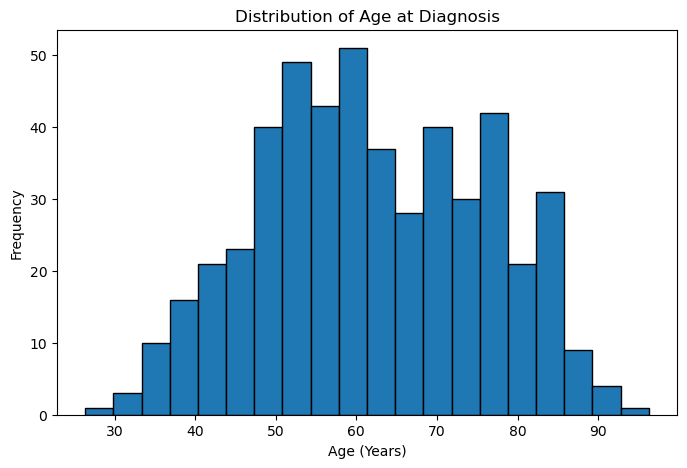

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(df["AGE_AT_DIAGNOSIS"],
         bins=20,
         edgecolor="black")

plt.title("Distribution of Age at Diagnosis")

plt.xlabel("Age (Years)")

plt.ylabel("Frequency")

plt.show()

### 5.1 Boxplot Analysis of Age at Diagnosis

A boxplot was created to further examine the distribution and variability of patient ages at breast cancer diagnosis. Unlike the histogram, which displays the frequency of observations across age groups, the boxplot provides a visual summary of the median, interquartile range (IQR), and potential outliers.

#### Visualization Method

The boxplot was generated using Matplotlib's `plt.boxplot()` function with the `AGE_AT_DIAGNOSIS` variable. The central line represents the median age, the box extends from the first to the third quartile, and the whiskers represent the range of observations within the plot's outlier boundaries.

#### Results and Interpretation

The boxplot shows a median age of approximately **60.87 years**, with the middle 50% of patients diagnosed between **51.42 and 73.22 years**. The interquartile range is approximately **21.80 years**, indicating considerable variation in age at diagnosis.

The whiskers extend from approximately **26.36 to 96.29 years**, representing the youngest and oldest patients in the dataset. No observations appear beyond the whiskers, indicating that no potential outliers were identified using the boxplot's default 1.5 × IQR criterion.

Together with the histogram, this visualization confirms that the study population includes a broad range of ages, with most diagnoses concentrated among middle-aged and older adults. These findings provide additional context for evaluating age as a predictor of overall survival status in the Bayesian logistic regression model.

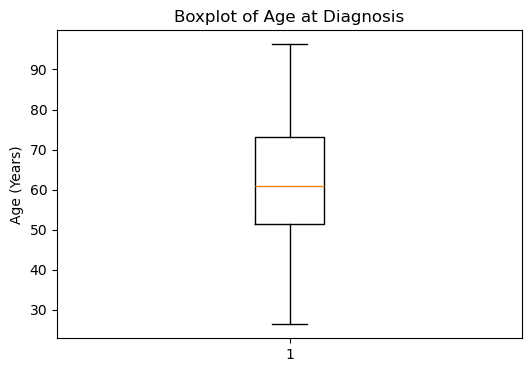

In [12]:
plt.figure(figsize=(6,4))

plt.boxplot(df["AGE_AT_DIAGNOSIS"])

plt.title("Boxplot of Age at Diagnosis")

plt.ylabel("Age (Years)")

plt.show()

### 5.2 Enhanced Boxplot with Statistical Annotations

To improve the interpretation of age at diagnosis, the original boxplot was expanded to include numerical annotations for the minimum, maximum, mean, median, quartiles, and interquartile range (IQR).

The statistics were calculated using Pandas functions, including `quantile()`, `median()`, `mean()`, `min()`, and `max()`. Matplotlib's `plt.text()` function was used to display the calculated values directly on the figure, while `plt.scatter()` added a red marker representing the mean.

The enhanced visualization confirms a **mean age of 61.98 years**, a **median of 60.87 years**, and an **IQR of 21.80 years**. The mean and median are relatively close, suggesting that the distribution is not strongly skewed.

Adding statistical annotations makes the visualization more informative by allowing readers to identify important measures of central tendency and variability without referring to a separate statistical table. This presentation also provides a useful reference for comparing patient age distributions across survival groups later in the analysis.

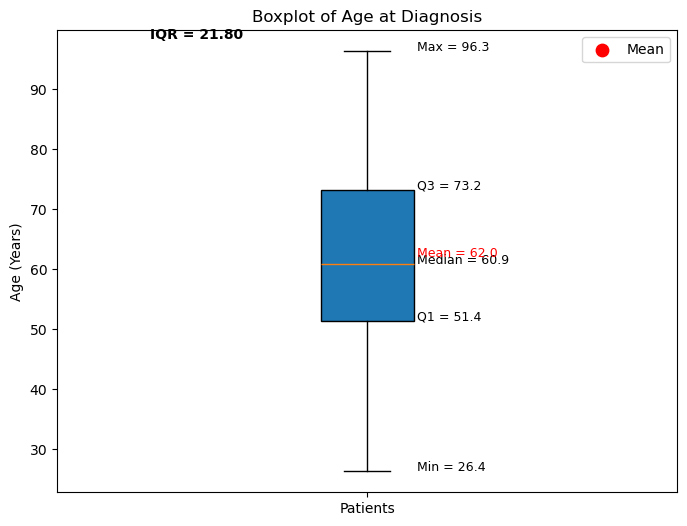

In [13]:
import matplotlib.pyplot as plt

# Calculate statistics
age = df["AGE_AT_DIAGNOSIS"]

minimum = age.min()
q1 = age.quantile(0.25)
median = age.median()
mean = age.mean()
q3 = age.quantile(0.75)
maximum = age.max()
iqr = q3 - q1

# Create figure
plt.figure(figsize=(8,6))

plt.boxplot(age, vert=True, patch_artist=True)

# Plot the mean
plt.scatter(1, mean, color='red', s=80, label='Mean')

# Add labels
plt.text(1.08, minimum, f"Min = {minimum:.1f}", fontsize=9)
plt.text(1.08, q1, f"Q1 = {q1:.1f}", fontsize=9)
plt.text(1.08, median, f"Median = {median:.1f}", fontsize=9)
plt.text(1.08, mean, f"Mean = {mean:.1f}", fontsize=9, color='red')
plt.text(1.08, q3, f"Q3 = {q3:.1f}", fontsize=9)
plt.text(1.08, maximum, f"Max = {maximum:.1f}", fontsize=9)

# Add IQR text
plt.text(0.65, maximum + 2,
         f"IQR = {iqr:.2f}",
         fontsize=10,
         fontweight='bold')

plt.title("Boxplot of Age at Diagnosis")
plt.ylabel("Age (Years)")
plt.xticks([1], ["Patients"])

plt.legend()

plt.show()

### 6. Distribution of Estrogen Receptor (ER) Status

Estrogen receptor (ER) status is an important biomarker in breast cancer pathology because it helps classify hormone receptor expression and guides endocrine treatment decisions. Examining the distribution of ER-positive and ER-negative patients provides an understanding of the biomarker composition of the METABRIC study population.

#### Visualization Method

The `value_counts()` function was used to calculate the number of patients in each ER category. A bar chart was generated using Matplotlib's `plt.bar()` function, with numerical labels added above each bar to display the patient counts.

#### Results and Interpretation

Among the **500 patients**, **388 (77.6%) were ER-positive**, while **112 (22.4%) were ER-negative**.

The results demonstrate that ER-positive breast cancers represent the majority of observations in this dataset. This is an important consideration for the subsequent Bayesian logistic regression because the unequal distribution of ER classifications may influence the precision of the estimated association between ER status and mortality.

Although ER status is clinically relevant to breast cancer prognosis and treatment selection, this distribution alone does not indicate whether ER-positive patients experienced better survival outcomes. That relationship requires additional analysis incorporating overall survival status.

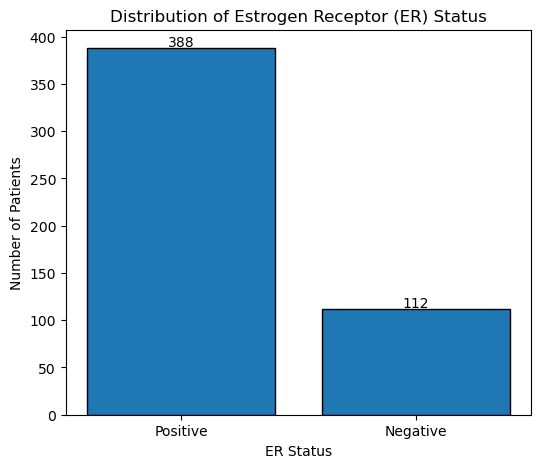

In [14]:
import matplotlib.pyplot as plt

# Count ER status
er_counts = df["ER_STATUS"].value_counts()

# Create figure
plt.figure(figsize=(6,5))

bars = plt.bar(er_counts.index,
               er_counts.values,
               edgecolor='black')

# Add labels above bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2,
             height + 2,
             f'{int(height)}',
             ha='center',
             fontsize=10)

plt.title("Distribution of Estrogen Receptor (ER) Status")
plt.xlabel("ER Status")
plt.ylabel("Number of Patients")

plt.show()

### 7. Distribution of Progesterone Receptor (PR) Status

Progesterone receptor (PR) status is another routinely evaluated breast cancer biomarker. Along with ER status, PR expression contributes to hormone receptor classification and provides information relevant to breast cancer prognosis and treatment planning.

#### Visualization Method

The distribution of PR status was examined using Pandas `value_counts()` to calculate the number of positive and negative classifications. Matplotlib's `plt.bar()` function was used to visualize these frequencies, with patient counts displayed above each bar.

#### Results and Interpretation

Of the **496 patients with available PR results**, **252 (50.8%) were PR-positive**, while **244 (49.2%) were PR-negative**. Four patients had missing PR classifications and were excluded from this frequency calculation.

Unlike ER status, which showed a substantial predominance of positive classifications, PR status was distributed almost equally between positive and negative groups.

This relatively balanced distribution provides representation of both PR categories for the subsequent Bayesian analysis. However, the frequency of PR expression does not establish its relationship with mortality.

Comparing PR status with overall survival outcomes will help determine whether differences in recorded mortality are observed between PR-positive and PR-negative patients. The Bayesian logistic regression will then evaluate PR status alongside age, ER status, and HER2 status.

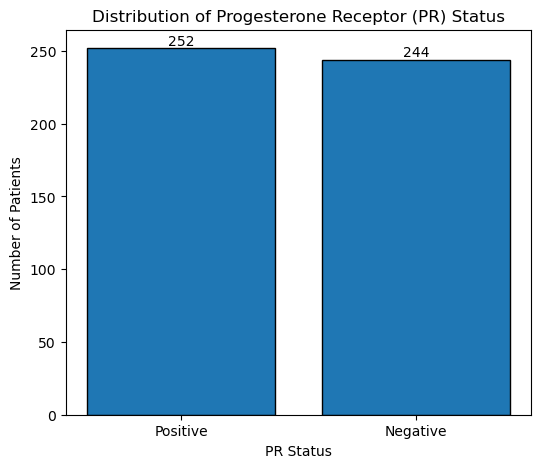

In [15]:
# Count PR status
pr_counts = df["PR_STATUS"].value_counts()

# Create figure
plt.figure(figsize=(6,5))

bars = plt.bar(pr_counts.index,
               pr_counts.values,
               edgecolor='black')

# Add labels above bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2,
             height + 2,
             f'{int(height)}',
             ha='center',
             fontsize=10)

plt.title("Distribution of Progesterone Receptor (PR) Status")
plt.xlabel("PR Status")
plt.ylabel("Number of Patients")

plt.show()

### 7.1 ER and PR Frequency Tables

To supplement the bar charts, frequency tables were created to summarize the number and percentage of patients classified as ER-positive, ER-negative, PR-positive, and PR-negative.

The tables were generated using Pandas `value_counts()` to calculate patient counts and `value_counts(normalize=True)` to determine the proportion of patients in each category. Percentages were multiplied by 100 and rounded to one decimal place for reporting.

The ER results confirmed that **388 patients (77.6%) were ER-positive**, compared with **112 (22.4%) who were ER-negative**, among all 500 records.

For PR status, **252 patients (50.8%) were PR-positive** and **244 (49.2%) were PR-negative**, based on 496 patients with available results.

These tables reinforce the differences observed in the bar charts, particularly the predominance of ER-positive classifications compared with the nearly equal distribution of PR status. Presenting both counts and percentages makes it easier to compare biomarker distributions while accounting for differences in the number of available observations.

In [16]:
er_table = pd.DataFrame({
    "Count": df["ER_STATUS"].value_counts(),
    "Percentage": round(df["ER_STATUS"].value_counts(normalize=True) * 100, 1)
})

er_table

,Count,Percentage
ER_STATUS,,
Positive,388,77.6
Negative,112,22.4


In [17]:
pr_table = pd.DataFrame({
    "Count": df["PR_STATUS"].value_counts(),
    "Percentage": round(df["PR_STATUS"].value_counts(normalize=True) * 100, 1)
})

pr_table

,Count,Percentage
PR_STATUS,,
Positive,252,50.8
Negative,244,49.2


### 8. Distribution of Human Epidermal Growth Factor Receptor 2 (HER2) Status

Human epidermal growth factor receptor 2 (HER2) is an important biomarker in breast cancer pathology because HER2 status helps guide molecular classification and eligibility for HER2-targeted therapies. Examining its distribution provides insight into the proportion of HER2-positive and HER2-negative patients represented in the METABRIC dataset.

#### Visualization and Statistical Methods

The `value_counts(dropna=False)` function was initially used to examine HER2 classifications while retaining missing values in the frequency count.

A bar chart was then created using Matplotlib's `plt.bar()` function, with patient counts displayed above each category. A separate Pandas DataFrame summarized the counts and percentages using `value_counts()` and `value_counts(normalize=True)`.

#### Results and Interpretation

Of the **500 original patient records**, 496 contained an available HER2 classification, while four records had missing values.

Among patients with available results:

- **444 patients (89.5%) were HER2-negative.**
- **52 patients (10.5%) were HER2-positive.**

The results demonstrate a substantial predominance of HER2-negative breast cancers in this dataset. Compared with ER and PR status, HER2 has the most uneven distribution between positive and negative classifications.

This difference is relevant to the subsequent Bayesian logistic regression because the relatively small HER2-positive group may result in greater uncertainty when estimating its association with mortality.

Although HER2 expression is clinically important for breast cancer classification and treatment selection, these descriptive findings do not establish whether HER2-positive patients experienced different survival outcomes. That relationship will be investigated through comparisons with overall survival status and the Bayesian regression model.

In [18]:
df["HER2_STATUS"].value_counts(dropna=False)

HER2_STATUS
Negative    444
Positive     52
NaN           4
Name: count, dtype: int64

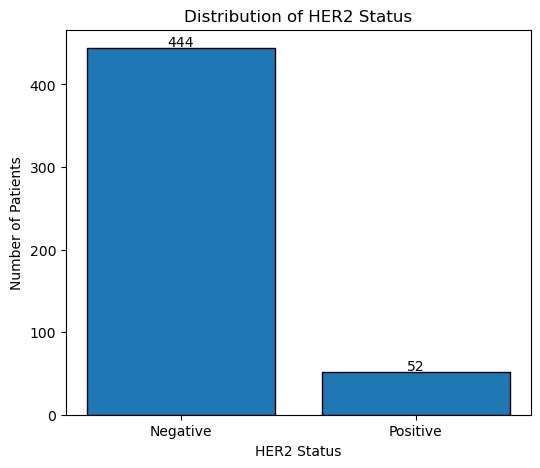

In [19]:
# Count HER2 status
her2_counts = df["HER2_STATUS"].value_counts()

# Create figure
plt.figure(figsize=(6,5))

bars = plt.bar(her2_counts.index,
               her2_counts.values,
               edgecolor='black')

# Add value labels above bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2,
             height + 2,
             f'{int(height)}',
             ha='center',
             fontsize=10)

plt.title("Distribution of HER2 Status")
plt.xlabel("HER2 Status")
plt.ylabel("Number of Patients")

plt.show()

In [20]:
her2_table = pd.DataFrame({
    "Count": df["HER2_STATUS"].value_counts(),
    "Percentage": round(df["HER2_STATUS"].value_counts(normalize=True) * 100, 1)
})

her2_table

,Count,Percentage
HER2_STATUS,,
Negative,444,89.5
Positive,52,10.5


### 9. Distribution of Overall Survival Status

Overall survival status (`OS_STATUS`) was examined to understand the distribution of living and deceased patients in the METABRIC dataset. This variable serves as the dependent outcome in the subsequent Bayesian logistic regression model, which investigates how age at diagnosis and breast cancer biomarker classifications are associated with recorded mortality.

#### Visualization and Statistical Methods

A frequency table was created using Pandas `value_counts()` to calculate the number of living and deceased patients. The `value_counts(normalize=True)` function was used to calculate the percentage of patients in each category.

A bar chart was then generated using Matplotlib's `plt.bar()` function, with patient counts displayed above each bar. Overall survival status was categorized as `0:LIVING` or `1:DECEASED`.

#### Results and Interpretation

Of the **500 original patient records**, 496 contained an available overall survival classification, while four records had missing values.

Among the 496 patients with recorded survival status:

- **288 patients (58.1%) were living.**
- **208 patients (41.9%) were deceased.**

The results show that living patients represented a slightly larger proportion of the study population, although both outcome categories were well represented.

This distribution is important for the Bayesian logistic regression because the model estimates the probability of recorded death based on the selected clinical predictors. Having observations in both outcome categories provides the foundation for examining differences in mortality across patient characteristics.

These findings describe the observed survival status within the dataset rather than a time-adjusted survival probability. Differences in follow-up duration and other clinical factors must be considered when interpreting mortality outcomes.

In [21]:
os_table = pd.DataFrame({
    "Count": df["OS_STATUS"].value_counts(),
    "Percentage": round(df["OS_STATUS"].value_counts(normalize=True)*100,1)
})

os_table

,Count,Percentage
OS_STATUS,,
0:LIVING,288,58.1
1:DECEASED,208,41.9


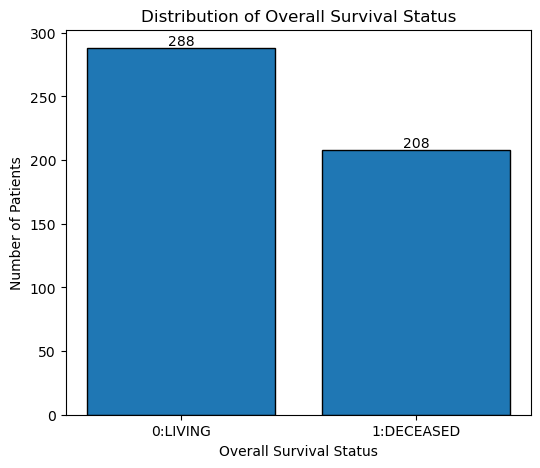

In [22]:
import matplotlib.pyplot as plt

# Count survival status
os_counts = df["OS_STATUS"].value_counts()

plt.figure(figsize=(6,5))

bars = plt.bar(os_counts.index,
               os_counts.values,
               edgecolor="black")

# Add count labels
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2,
             height + 2,
             f"{int(height)}",
             ha="center",
             fontsize=10)

plt.title("Distribution of Overall Survival Status")
plt.xlabel("Overall Survival Status")
plt.ylabel("Number of Patients")

plt.show()

### 10. Relationship Between Clinical Biomarkers and Overall Survival Status

Following the individual biomarker and survival status analyses, contingency tables were created to examine how recorded mortality differed across estrogen receptor (ER), progesterone receptor (PR), and HER2 classifications.

These comparisons provide an initial understanding of potential relationships between biomarker expression and patient outcomes before developing the Bayesian logistic regression model.

#### Statistical Method

The Pandas `pd.crosstab()` function was used to create contingency tables comparing each biomarker classification with `OS_STATUS`.

Each table displays the number of living and deceased patients within the positive and negative biomarker categories. Mortality proportions were also calculated from these counts to support comparisons between groups.

#### Estrogen Receptor (ER) Status and Overall Survival

Among **112 ER-negative patients**, 58 were living and 54 were deceased, representing a recorded mortality proportion of **48.2%**.

Among **384 ER-positive patients with available survival status**, 230 were living and 154 were deceased, representing a mortality proportion of **40.1%**.

The results indicate that ER-negative patients had a higher observed proportion of deaths than ER-positive patients in this dataset.

Although this difference suggests a possible association between ER classification and mortality, additional statistical modeling is needed to determine whether the relationship remains evident after accounting for age and other biomarkers.

#### Progesterone Receptor (PR) Status and Overall Survival

Among **244 PR-negative patients**, 129 were living and 115 were deceased, representing a mortality proportion of **47.1%**.

Among **252 PR-positive patients**, 159 were living and 93 were deceased, representing a mortality proportion of **36.9%**.

The observed mortality proportion was higher among PR-negative patients, with a difference of approximately **10.2 percentage points** between the two groups.

This descriptive finding suggests that PR status may be associated with overall survival status. However, the contingency table does not account for other clinical characteristics that may influence mortality.

#### HER2 Status and Overall Survival

Among **444 HER2-negative patients**, 263 were living and 181 were deceased, representing a mortality proportion of **40.8%**.

Among **52 HER2-positive patients**, 25 were living and 27 were deceased, representing a mortality proportion of **51.9%**.

HER2-positive patients had a higher observed proportion of deaths than HER2-negative patients, with a difference of approximately **11.2 percentage points**.

The smaller HER2-positive group is an important consideration because estimates based on fewer observations may have greater statistical uncertainty.

#### Overall Interpretation

The contingency tables reveal differences in recorded mortality across all three biomarker classifications. ER-negative and PR-negative patients had higher observed mortality proportions than their positive counterparts, while HER2-positive patients had a higher observed mortality proportion than HER2-negative patients.

These findings are descriptive and do not establish statistical significance, causation, or independent predictive relationships.

The subsequent Bayesian logistic regression will evaluate ER, PR, and HER2 status together with age at diagnosis, allowing the associations between these predictors and recorded mortality to be estimated within a multivariable statistical framework.

In [23]:
pd.crosstab(df["ER_STATUS"], df["OS_STATUS"])

OS_STATUS,0:LIVING,1:DECEASED
ER_STATUS,,
Negative,58,54
Positive,230,154


In [24]:
pd.crosstab(df["PR_STATUS"], df["OS_STATUS"])

OS_STATUS,0:LIVING,1:DECEASED
PR_STATUS,,
Negative,129,115
Positive,159,93


In [25]:
pd.crosstab(df["HER2_STATUS"], df["OS_STATUS"])

OS_STATUS,0:LIVING,1:DECEASED
HER2_STATUS,,
Negative,263,181
Positive,25,27


### 10.1 Visualization of Overall Survival by Estrogen Receptor (ER) Status

A grouped bar chart was created to visualize differences in recorded overall survival status between ER-positive and ER-negative patients. This visualization builds on the contingency table presented in Section 10 and provides a clearer comparison of living and deceased patients within each ER classification.

#### Visualization Method

The Pandas `pd.crosstab()` function was used to organize ER status and overall survival into a contingency table. The resulting DataFrame was visualized using `.plot(kind="bar")`, with separate bars representing living and deceased patients.

Matplotlib's `ax.bar_label()` function was used to display patient counts above each bar, making the results easier to interpret without referring to the original table.

#### Results and Interpretation

Among ER-negative patients, **58 were living and 54 were deceased**, representing a recorded mortality proportion of **48.2%**. In comparison, among ER-positive patients with available survival information, **230 were living and 154 were deceased**, representing a mortality proportion of **40.1%**.

The visualization shows that ER-positive patients accounted for a larger number of both living and deceased observations because they represented the majority of the study population. However, when accounting for the different group sizes, ER-negative patients had a higher observed proportion of deaths.

This distinction demonstrates why comparing mortality proportions is more informative than comparing patient counts alone. The findings provide an initial indication of a possible relationship between ER classification and mortality, which will be evaluated alongside other clinical predictors in the Bayesian logistic regression model.

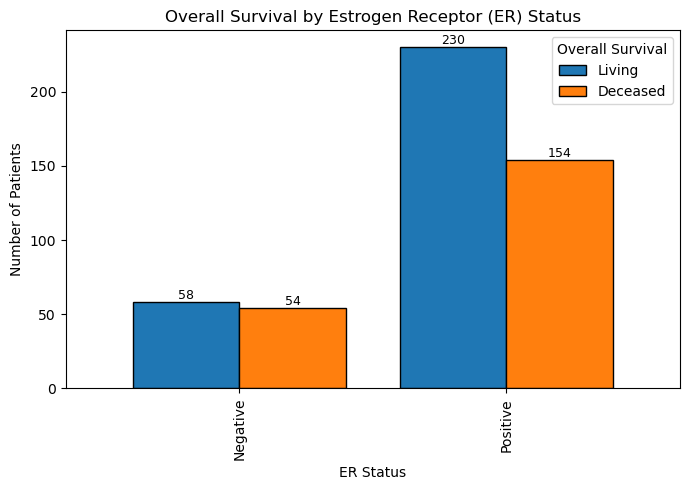

In [27]:
import matplotlib.pyplot as plt
import pandas as pd

# Create contingency table
er_survival = pd.crosstab(df["ER_STATUS"], df["OS_STATUS"])

# Create grouped bar chart
ax = er_survival.plot(
    kind="bar",
    figsize=(7,5),
    edgecolor="black",
    width=0.8
)

# Add labels above bars
for container in ax.containers:
    ax.bar_label(container, fontsize=9)

plt.title("Overall Survival by Estrogen Receptor (ER) Status")
plt.xlabel("ER Status")
plt.ylabel("Number of Patients")
plt.legend(["Living", "Deceased"], title="Overall Survival")

plt.tight_layout()
plt.show()

### 10.2 Visualization of Overall Survival by Progesterone Receptor (PR) Status

A second grouped bar chart was developed to compare overall survival status between PR-positive and PR-negative patients. Unlike the ER distribution, which was predominantly positive, the PR categories were more evenly represented, allowing a clearer visual comparison of patient counts between the two groups.

#### Visualization Method

The `pd.crosstab()` function was used to summarize living and deceased patients by PR classification. The resulting contingency table was displayed using Pandas `.plot(kind="bar")`, with separate bars for each survival outcome.

Numerical labels were added using Matplotlib's `ax.bar_label()` function to identify the number of patients in each category.

#### Results and Interpretation

Among PR-negative patients, **129 were living and 115 were deceased**, corresponding to a recorded mortality proportion of **47.1%**.

Among PR-positive patients, **159 were living and 93 were deceased**, corresponding to a mortality proportion of **36.9%**.

The grouped bar chart illustrates a higher number of living patients among PR-positive cases and a higher number of deceased patients among PR-negative cases.

When comparing mortality proportions, PR-negative patients had an observed mortality proportion approximately **10.2 percentage points higher** than PR-positive patients.

These findings suggest a possible association between PR classification and recorded mortality within the study population. However, the descriptive comparison does not account for age, ER status, HER2 status, or other clinical characteristics that may influence patient outcomes.

The subsequent Bayesian logistic regression will provide a multivariable assessment of these relationships while quantifying uncertainty in the estimated associations.

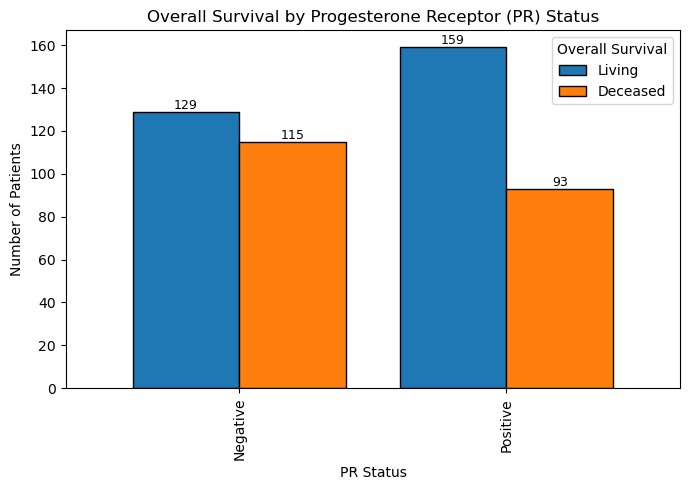

In [28]:
# Create contingency table
pr_survival = pd.crosstab(df["PR_STATUS"], df["OS_STATUS"])

# Create grouped bar chart
ax = pr_survival.plot(
    kind="bar",
    figsize=(7,5),
    edgecolor="black",
    width=0.8
)

# Add labels
for container in ax.containers:
    ax.bar_label(container, fontsize=9)

plt.title("Overall Survival by Progesterone Receptor (PR) Status")
plt.xlabel("PR Status")
plt.ylabel("Number of Patients")
plt.legend(["Living", "Deceased"], title="Overall Survival")

plt.tight_layout()
plt.show()

### 10.3 Visualization of Overall Survival by HER2 Status

A grouped bar chart was created to compare recorded overall survival status between HER2-positive and HER2-negative patients. This visualization completes the exploratory comparisons of the three primary breast cancer biomarkers and their relationships with mortality in the METABRIC dataset.

#### Visualization Method

The Pandas `pd.crosstab()` function was used to organize HER2 classifications and overall survival status into a contingency table. The resulting DataFrame was visualized using `.plot(kind="bar")`, with separate bars representing living and deceased patients.

Matplotlib's `ax.bar_label()` function was used to display patient counts above each bar, allowing the survival outcomes to be compared across HER2 classifications.

#### Results and Interpretation

Among **444 HER2-negative patients**, 263 were living and 181 were deceased, representing a recorded mortality proportion of **40.8%**.

Among **52 HER2-positive patients**, 25 were living and 27 were deceased, representing a mortality proportion of **51.9%**.

The visualization shows that HER2-negative patients accounted for substantially more observations overall. However, within the HER2-positive group, the number of deceased patients was slightly higher than the number of living patients.

When accounting for differences in group size, HER2-positive patients had an observed mortality proportion approximately **11.2 percentage points higher** than HER2-negative patients.

This finding suggests a possible association between HER2 classification and recorded mortality within the study population. However, the relatively small HER2-positive group may contribute to greater uncertainty in estimating this relationship.

Together with the ER and PR comparisons, these results provide a foundation for the subsequent Bayesian logistic regression, which will evaluate the associations between age, receptor classifications, and recorded mortality while accounting for the other predictors included in the model.

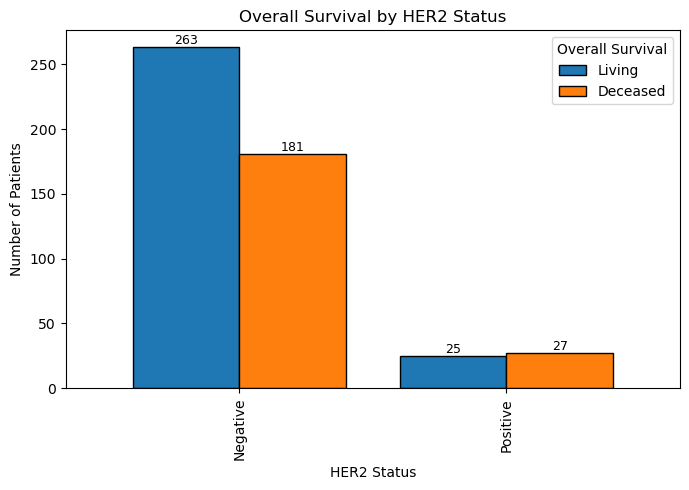

In [29]:
# Create contingency table
her2_survival = pd.crosstab(df["HER2_STATUS"], df["OS_STATUS"])

# Create grouped bar chart
ax = her2_survival.plot(
    kind="bar",
    figsize=(7,5),
    edgecolor="black",
    width=0.8
)

# Add labels
for container in ax.containers:
    ax.bar_label(container, fontsize=9)

plt.title("Overall Survival by HER2 Status")
plt.xlabel("HER2 Status")
plt.ylabel("Number of Patients")
plt.legend(["Living", "Deceased"], title="Overall Survival")

plt.tight_layout()
plt.show()

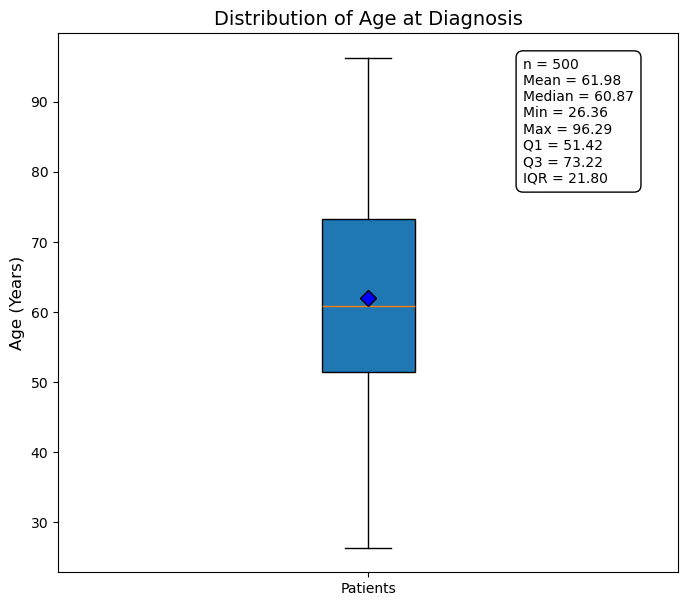

In [32]:
import matplotlib.pyplot as plt

# Age data
age = df["AGE_AT_DIAGNOSIS"]

# Calculate descriptive statistics
minimum = age.min()
maximum = age.max()
mean = age.mean()
median = age.median()
q1 = age.quantile(0.25)
q3 = age.quantile(0.75)
iqr = q3 - q1

# Create figure
fig, ax = plt.subplots(figsize=(8,7))

ax.boxplot(
    age,
    vert=True,
    patch_artist=True,
    showmeans=True,
    meanprops=dict(
        marker='D',
        markerfacecolor='blue',
        markeredgecolor='black',
        markersize=8
    )
)

# Statistics box
stats_text = (
    f"n = {len(age)}\n"
    f"Mean = {mean:.2f}\n"
    f"Median = {median:.2f}\n"
    f"Min = {minimum:.2f}\n"
    f"Max = {maximum:.2f}\n"
    f"Q1 = {q1:.2f}\n"
    f"Q3 = {q3:.2f}\n"
    f"IQR = {iqr:.2f}"
)

ax.text(
    1.25,
    maximum,
    stats_text,
    fontsize=10,
    verticalalignment='top',
    bbox=dict(
        facecolor='white',
        edgecolor='black',
        boxstyle='round,pad=0.5'
    )
)

# Titles
ax.set_title("Distribution of Age at Diagnosis", fontsize=14)
ax.set_ylabel("Age (Years)", fontsize=12)
ax.set_xticks([1])
ax.set_xticklabels(["Patients"])

plt.show()

## 11. Age at Diagnosis by Overall Survival Status

Age at diagnosis was compared between living and deceased patients to examine whether differences in patient age were associated with recorded mortality in the METABRIC dataset. This analysis builds on the earlier age distribution findings by examining age separately for each survival group.

### Visualization Method

Side-by-side boxplots were generated using Matplotlib to compare the age distributions of living and deceased patients. The `OS_STATUS` variable was used to separate the groups, while `AGE_AT_DIAGNOSIS` provided the numerical values.

Each boxplot displays the median, quartiles, and potential outliers. Mean values were added as diamond-shaped markers, and separate statistical summaries were included to make the distributions easier to compare.

### Results and Interpretation

Among the **288 living patients**, the mean age at diagnosis was **57.4 years**, with a median of **56.8 years**. In comparison, the **208 deceased patients** had a mean age of **68.3 years** and a median of **70.2 years**.

The difference in mean age was approximately **10.9 years**, indicating that patients classified as deceased were generally older at diagnosis than those classified as living.

The middle 50% of ages ranged from **49.2 to 65.5 years** among living patients and **58.8 to 79.3 years** among deceased patients. The deceased group also had a larger interquartile range of **20.5 years**, compared with **16.3 years** for living patients.

One potential outlier was identified in the deceased group at approximately **26.4 years**. Although this patient was considerably younger than others in the group, the observation was retained because an unusual age does not necessarily indicate an inaccurate clinical record.

These findings suggest an association between older age at diagnosis and recorded mortality within the study population. However, this descriptive comparison does not establish that age independently predicts mortality or accounts for differences in follow-up time.

The subsequent Bayesian logistic regression will evaluate age alongside ER, PR, and HER2 classifications to estimate their associations with recorded mortality while accounting for the other included predictors.

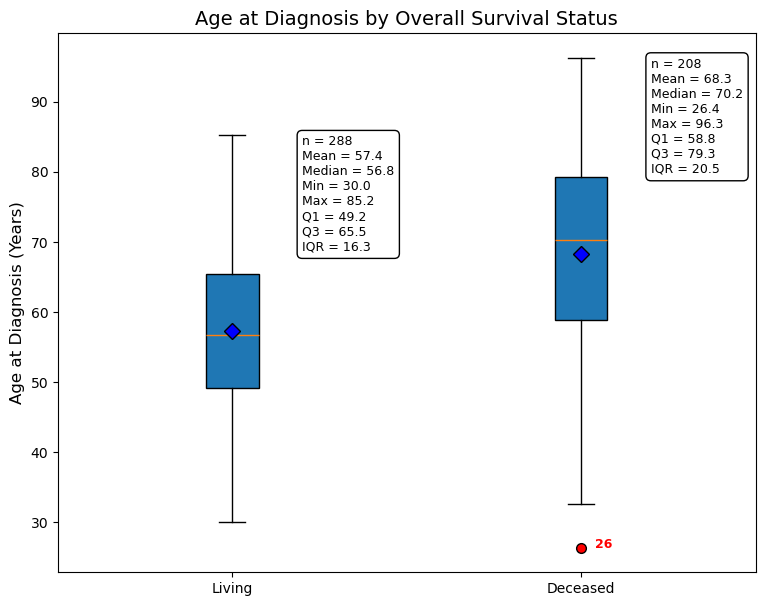

In [36]:
import matplotlib.pyplot as plt

living = df[df["OS_STATUS"] == "0:LIVING"]["AGE_AT_DIAGNOSIS"]
deceased = df[df["OS_STATUS"] == "1:DECEASED"]["AGE_AT_DIAGNOSIS"]

groups = [living, deceased]
labels = ["Living", "Deceased"]

fig, ax = plt.subplots(figsize=(9,7))

# Create boxplot and save output
bp = ax.boxplot(
    groups,
    patch_artist=True,
    showmeans=True,
    meanprops=dict(
        marker='D',
        markerfacecolor='blue',
        markeredgecolor='black',
        markersize=8
    ),
    flierprops=dict(
        marker='o',
        markerfacecolor='red',
        markeredgecolor='black',
        markersize=7
    )
)

# Add labels to each outlier
for flier in bp["fliers"]:
    x = flier.get_xdata()
    y = flier.get_ydata()

    for xi, yi in zip(x, y):
        ax.text(
            xi + 0.04,
            yi,
            f"{yi:.0f}",
            color="red",
            fontsize=9,
            fontweight="bold"
        )

# Statistics boxes
for i, data in enumerate(groups, start=1):

    minimum = data.min()
    maximum = data.max()
    mean = data.mean()
    median = data.median()
    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1

    stats_text = (
        f"n = {len(data)}\n"
        f"Mean = {mean:.1f}\n"
        f"Median = {median:.1f}\n"
        f"Min = {minimum:.1f}\n"
        f"Max = {maximum:.1f}\n"
        f"Q1 = {q1:.1f}\n"
        f"Q3 = {q3:.1f}\n"
        f"IQR = {iqr:.1f}"
    )

    ax.text(
        i + 0.20,
        maximum,
        stats_text,
        fontsize=9,
        va="top",
        bbox=dict(
            facecolor="white",
            edgecolor="black",
            boxstyle="round,pad=0.4"
        )
    )

ax.set_title("Age at Diagnosis by Overall Survival Status", fontsize=14)
ax.set_ylabel("Age at Diagnosis (Years)", fontsize=12)
ax.set_xticklabels(labels)

plt.show()

## 12. Conclusion: Exploratory Data Analysis

The exploratory analysis of the METABRIC breast cancer dataset provided a clearer understanding of the patient population, clinical characteristics, and relationships between breast cancer biomarkers and recorded mortality. The original dataset contained 500 patient records and 39 variables. After addressing missing values in the selected model variables, 496 complete records remained available for further analysis.

The results showed that ER-positive tumors were more common than ER-negative tumors, while PR classifications were distributed more evenly. Most patients were also classified as HER2-negative. When these biomarkers were compared with overall survival status, differences in observed mortality became apparent. ER-negative and PR-negative patients had higher proportions of recorded deaths than their positive counterparts, while HER2-positive patients had a higher mortality proportion than HER2-negative patients.

Age at diagnosis also showed an important pattern. Patients classified as deceased were generally older at diagnosis, with a mean age of 68.3 years compared with 57.4 years among living patients. These findings suggest that both age and receptor classifications may be associated with recorded mortality, although the descriptive results cannot establish independent predictive relationships or account for differences in follow-up time.

Overall, this analysis established a foundation for examining breast cancer outcomes using a more comprehensive statistical approach. **Part 2 will build on these findings through Bayesian logistic regression**, evaluating age at diagnosis, ER status, PR status, and HER2 status together to estimate their associations with recorded mortality while accounting for uncertainty in the model estimates.